In [1]:
import sys
print(sys.executable)

c:\Users\Admin\Desktop\parcours-ia\.venv\Scripts\python.exe


In [2]:
import pandas as pd
pd.__version__

'3.1.0'

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

for police in Path("../../style/polices").glob("*.ttf"):
    fm.fontManager.addfont(police)
plt.style.use("../../style/quiet-light.mplstyle")


In [4]:
commandes = pd.read_csv("donnees/DataCoSupplyChainDataset.csv", encoding = "latin-1")
commandes.shape

(180519, 53)

In [5]:
colonnes_identite_client = ["Customer Fname", "Customer Lname", "Customer Street",
                            "Customer Email", "Customer Password"]
commandes = commandes.drop(columns=colonnes_identite_client)
commandes.shape

(180519, 48)

In [6]:
commandes.head(3).T

,0,1,2
Type,DEBIT,TRANSFER,CASH
Days for shipping (real),3,5,4
Days for shipment (scheduled),4,4,4
Benefit per order,91.25,-249.089996,-247.779999
Sales per customer,314.640015,311.359985,309.720001
Delivery Status,Advance shipping,Late delivery,Shipping on time
Late_delivery_risk,0,1,0
Category Id,73,73,73
Category Name,Sporting Goods,Sporting Goods,Sporting Goods
Customer City,Caguas,Caguas,San Jose


In [7]:
commandes["Late_delivery_risk"].mean()

np.float64(0.5482913155955883)

In [8]:
retard_par_mode = commandes.groupby("Shipping Mode")["Late_delivery_risk"].mean().sort_values()
retard_par_mode

Shipping Mode
Standard Class    0.380717
Same Day          0.457430
Second Class      0.766328
First Class       0.953225
Name: Late_delivery_risk, dtype: float64

In [9]:
commandes["date_commande"] = pd.to_datetime(commandes["order date (DateOrders)"], format="%m/%d/%Y %H:%M")
commandes["date_commande"].min(), commandes["date_commande"].max()


(Timestamp('2015-01-01 00:00:00'), Timestamp('2018-01-31 23:38:00'))

In [10]:
est_entrainement = commandes["date_commande"] < "2017-01-01"
est_validation = (commandes["date_commande"] >= "2017-01-01") & (commandes["date_commande"] < "2017-07-01")
est_test_scelle = commandes["date_commande"] >= "2017-07-01"

est_entrainement.sum(), est_validation.sum(), est_test_scelle.sum()


(np.int64(125200), np.int64(30950), np.int64(24369))

In [11]:
from sklearn.metrics import accuracy_score

vraies_valeurs = commandes.loc[est_validation, "Late_delivery_risk"]

prediction_toujours_en_retard = [1] * len(vraies_valeurs)
accuracy_score(vraies_valeurs, prediction_toujours_en_retard)


0.5405169628432956

In [12]:
prediction_regle_du_mode = commandes.loc[est_validation, "Shipping Mode"].isin(["First Class", "Second Class"]).astype(int)
accuracy_score(vraies_valeurs, prediction_regle_du_mode)

0.6873667205169628

In [13]:
commandes.nunique().sort_values()

Product Description                   0
Product Status                        1
Late_delivery_risk                    2
Customer Country                      2
Customer Segment                      3
Days for shipment (scheduled)         4
Delivery Status                       4
Type                                  4
Shipping Mode                         4
Order Item Quantity                   5
Market                                5
Days for shipping (real)              7
Order Status                          9
Department Name                      11
Department Id                        11
Order Item Discount Rate             18
Order Region                         23
Customer State                       46
Category Name                        50
Product Category Id                  51
Category Id                          51
Product Price                        75
Order Item Product Price             75
Order Item Cardprod Id              118
Product Card Id                     118


In [14]:
commandes["mois_commande"] = commandes["date_commande"].dt.month
commandes["jour_semaine_commande"] = commandes["date_commande"].dt.day_of_week
commandes["heure_commande"] = commandes["date_commande"].dt.hour

colonnes_a_exclure = [
    "Product Description", "Product Status", "Product Image",
    "Order Id", "Order Item Id", "Customer Id", "Order Customer Id", "Order Item Cardprod Id",
    "Product Card Id", "Product Category Id", "Category Id", "Department Id",
    "order date (DateOrders)", "shipping date (DateOrders)", "date_commande",
]
colonnes_candidates = [c for c in commandes.columns if c not in colonnes_a_exclure + ["Late_delivery_risk"]]
len(colonnes_candidates)


36

In [15]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

variables = commandes[colonnes_candidates].copy()
for colonne in variables.columns:
    if not pd.api.types.is_numeric_dtype(variables[colonne]):
        variables[colonne] = variables[colonne].astype("category")
        if variables[colonne].nunique() > 255:
            variables[colonne] = variables[colonne].cat.codes

modele = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0)
modele.fit(variables[est_entrainement], commandes.loc[est_entrainement, "Late_delivery_risk"])

probabilites = modele.predict_proba(variables[est_validation])[:, 1]
accuracy_score(vraies_valeurs, probabilites > 0.5), roc_auc_score(vraies_valeurs, probabilites)


(1.0, 1.0)

In [16]:
for numero, colonne in enumerate(colonnes_candidates, start=1):
    print(numero, colonne)

1 Type
2 Days for shipping (real)
3 Days for shipment (scheduled)
4 Benefit per order
5 Sales per customer
6 Delivery Status
7 Category Name
8 Customer City
9 Customer Country
10 Customer Segment
11 Customer State
12 Customer Zipcode
13 Department Name
14 Latitude
15 Longitude
16 Market
17 Order City
18 Order Country
19 Order Item Discount
20 Order Item Discount Rate
21 Order Item Product Price
22 Order Item Profit Ratio
23 Order Item Quantity
24 Sales
25 Order Item Total
26 Order Profit Per Order
27 Order Region
28 Order State
29 Order Status
30 Order Zipcode
31 Product Name
32 Product Price
33 Shipping Mode
34 mois_commande
35 jour_semaine_commande
36 heure_commande


In [17]:
colonnes_qui_fuient = ["Delivery Status", "Days for shipping (real)", "Order Status"]
colonnes_honnetes = [c for c in colonnes_candidates if c not in colonnes_qui_fuient]

variables_honnetes = variables[colonnes_honnetes]
modele_honnete = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0)
modele_honnete.fit(variables_honnetes[est_entrainement], commandes.loc[est_entrainement, "Late_delivery_risk"])

probabilites_honnetes = modele_honnete.predict_proba(variables_honnetes[est_validation])[:, 1]
accuracy_score(vraies_valeurs, probabilites_honnetes > 0.5), roc_auc_score(vraies_valeurs, probabilites_honnetes)


(0.7054281098546042, 0.7546946160337905)

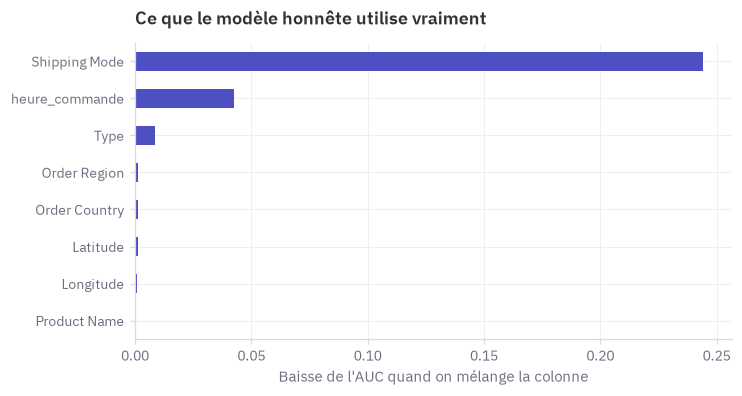

In [18]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

Path("resultats").mkdir(exist_ok=True)

importance = permutation_importance(
    modele_honnete, variables_honnetes[est_validation], vraies_valeurs,
    scoring="roc_auc", n_repeats=3, random_state=0)
importance_par_colonne = pd.Series(importance.importances_mean, index=colonnes_honnetes).sort_values()

axe = importance_par_colonne.tail(8).plot.barh(figsize=(7, 3.5))
axe.set_xlabel("Baisse de l'AUC quand on mélange la colonne")
axe.set_title("Ce que le modèle honnête utilise vraiment")
plt.savefig("resultats/importance_variables.png", dpi=150, bbox_inches="tight")
plt.show()


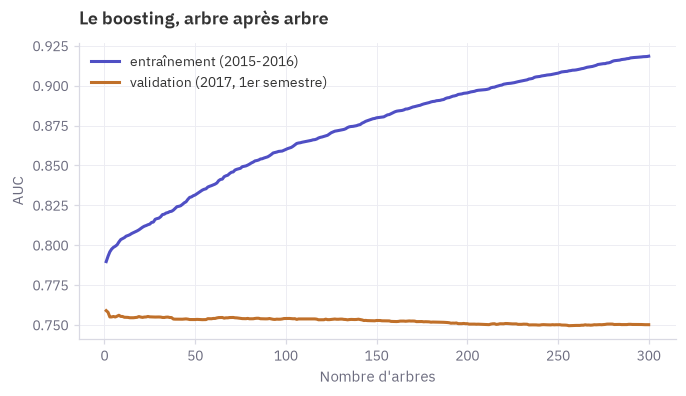

In [19]:
modele_courbe = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0,
                                               max_iter=300, early_stopping=False)
modele_courbe.fit(variables_honnetes[est_entrainement], commandes.loc[est_entrainement, "Late_delivery_risk"])

vraies_entrainement = commandes.loc[est_entrainement, "Late_delivery_risk"]
auc_entrainement = [roc_auc_score(vraies_entrainement, p[:, 1])
                    for p in modele_courbe.staged_predict_proba(variables_honnetes[est_entrainement])]
auc_validation = [roc_auc_score(vraies_valeurs, p[:, 1])
                  for p in modele_courbe.staged_predict_proba(variables_honnetes[est_validation])]

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, 301), auc_entrainement, label="entraînement (2015-2016)")
plt.plot(range(1, 301), auc_validation, label="validation (2017, 1er semestre)")
plt.xlabel("Nombre d'arbres")
plt.ylabel("AUC")
plt.title("Le boosting, arbre après arbre")
plt.legend()
plt.savefig("resultats/boosting_arbre_par_arbre.png", dpi=150, bbox_inches="tight")
plt.show()


In [20]:
# Test scellé : on entraîne sur entraînement + validation, on note UNE fois sur le test
vraies_test = commandes.loc[est_test_scelle, "Late_delivery_risk"]
modele_final = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0)
modele_final.fit(variables_honnetes[est_entrainement | est_validation],
                 commandes.loc[est_entrainement | est_validation, "Late_delivery_risk"])
probabilites_test = modele_final.predict_proba(variables_honnetes[est_test_scelle])[:, 1]
exactitude_test = accuracy_score(vraies_test, probabilites_test > 0.5)
auc_test = roc_auc_score(vraies_test, probabilites_test)
exactitude_test, auc_test


(0.7219007755755262, 0.7736820248100259)

In [21]:
scores = pd.DataFrame([
    {"modele": "Toujours en retard", "morceau": "validation", "exactitude": accuracy_score(vraies_valeurs, prediction_toujours_en_retard), "auc": None},
    {"modele": "Règle du mode", "morceau": "validation", "exactitude": accuracy_score(vraies_valeurs, prediction_regle_du_mode), "auc": None},
    {"modele": "Boosting, toutes les colonnes (fuite)", "morceau": "validation", "exactitude": accuracy_score(vraies_valeurs, probabilites > 0.5), "auc": roc_auc_score(vraies_valeurs, probabilites)},
    {"modele": "Boosting honnête", "morceau": "validation", "exactitude": accuracy_score(vraies_valeurs, probabilites_honnetes > 0.5), "auc": roc_auc_score(vraies_valeurs, probabilites_honnetes)},
    {"modele": "Boosting honnête", "morceau": "test scellé", "exactitude": exactitude_test, "auc": auc_test},
])
scores.to_csv("resultats/scores.csv", index=False)
scores.round(3)

,modele,morceau,exactitude,auc
0,Toujours en retard,validation,0.541,NaN
1,Règle du mode,validation,0.687,NaN
2,"Boosting, toutes les colonnes (fuite)",validation,1.000,1.000
3,Boosting honnête,validation,0.705,0.755
4,Boosting honnête,test scellé,0.722,0.774


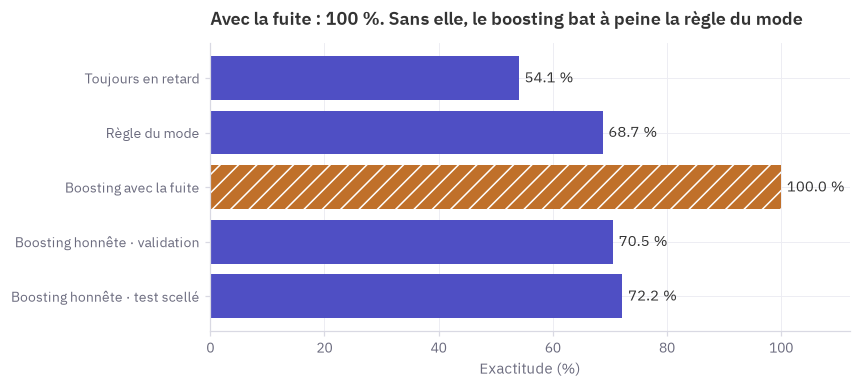

In [22]:
etiquettes = ["Toujours en retard", "Règle du mode", "Boosting avec la fuite",
              "Boosting honnête · validation", "Boosting honnête · test scellé"]
fig, axe = plt.subplots(figsize=(7.5, 3.4))
barres = axe.barh(etiquettes[::-1], 100 * scores["exactitude"].values[::-1])
barres[2].set_facecolor("C1")   # la barre de la fuite en orange hachuré
barres[2].set_hatch("//")
for barre in barres:
    axe.text(barre.get_width() + 1, barre.get_y() + barre.get_height() / 2, f"{barre.get_width():.1f} %", va="center")
axe.set_xlim(0, 112)
axe.set_xlabel("Exactitude (%)")
axe.set_title("Avec la fuite : 100 %. Sans elle, le boosting bat à peine la règle du mode")
plt.savefig("resultats/scores_et_fuite.png")
plt.show()
